# Stopping model: time-varying bound, sensory noise, guesses, and lapses

**Status (2026-10-09, model version 2):** `pigeon/stopping.py` (tests in
`tests/test_stopping.py`). Focus: OL (blocks 1–6) and MX (blocks 1–3). Bound
parameters are per block; guess, lapse, anticipation, sensory noise and NDT are
shared across a subject's blocks. Trials follow the paper's conventions. Fits
and recovery are run by scripts and cached in `data/processed/`. MXSC and the
change-point blocks come after OL and MX are settled.

## Why this notebook

Every bound analysis in the paper treats each trial as a bound crossing and handles
guessing only by filtering (`DT >= 2`, `trial_number >= 10`, the `rt_below_cutoff`
from `get_bounds`). This notebook fits an explicit trial-level model of *when*
subjects stop and *which* side they choose, so that guesses are estimated rather
than filtered.

**Why not accuracy or congruence.** With Gaussian steps of mean ±μ, the
likelihood ratio for "right" vs. "left" depends only on the current position `x`.
So for a subject who chooses the side the pigeon is on, P(correct | x at commit)
= logistic(2μ|x|/σ²), *whatever* rule decided when to stop. Accuracy (and
congruence) therefore cannot separate a low bound from evidence-independent
stopping; only the timing of commitments can. A bound-based rule and a
random-timing rule both give accuracy that rises with SNR and with commit time
(see `scratchpad/acc_policy.py` from the 2026-10-09 session).

## Task facts the model relies on

- Steps are Gaussian: `move_pigeon_function` in both `task/OL-MX-PD/PigeonTask.js`
  and `task/MXSC/PigeonTask.js` draws `step_mean + step_std * N(0, 1)` (Marsaglia
  polar method).
- `steps` records the *displayed* position, clamped at ±0.75 (`EDGE_DISTANCE`);
  the walk itself is not clamped. Once at the wall the pigeon stays at the edge
  until the key press, so a long RT after a wall hit says nothing about stopping.
  Wall hits are common in OL/MX (11–14% of trials) and rare in MXSC (49 trials).
- A response is possible on the trial's first frame, before any step (RT = 1):
  14% of OL trials, 11% of MX, 2% of MXSC. These are commits with no evidence
  (anticipations).
- Each position is shown for 200 ms (`UPDATE_INTERVAL = 0.2` in both task
  versions), so an NDT of n steps means the key press came 200·n to 200·(n+1) ms
  after the commit position appeared.
- **Datasets:** OL, MX and MXSC. Not PD: there the bound is set before the trial,
  so there is no voluntary stopping to model.

## Model (version 2)

Notation: `x_j` is the on-screen position after `j` steps (`x_0 = 0`).

1. **Anticipation.** With probability `a` the subject commits before any step is
   shown (choice random; response within the first NDT + 1 frames).
2. **Bound.** The bound at step `j` is `b_j = m · θ(j)`. The trial's multiplier `m`
   is gamma-distributed with mean 1 and coefficient of variation `bound_cv`
   (trial-to-trial bound variability). The time course is
   `θ(j) = bound_scale · h(j)`, with `log h` piecewise linear through knots at
   steps 1, 6 and 16 (constant outside them) and `h(6) = 1`, so `bound_scale` is
   the mean bound at step 6 (about the median commit step, where the level is
   best determined). A penalty on each log change (prior SD 0.5) keeps the time
   course near flat unless the data say otherwise; with 33–150 trials per block,
   an unpenalized curve trades an extreme early bound against a steep collapse.
3. **Sensory noise.** The subject sees `y_j = x_j + e_j`, with independent
   `e_j ~ N(0, sensory_std²)`, and commits at the first `j ≥ 1` with `|y_j| ≥ b_j`,
   choosing the side crossed. This lets commits happen away from the pigeon's
   visible maximum and makes choices near the center noisy (the incongruence that
   Figure03S03 attributes to sensory noise).
4. **Guess.** If the bound isn't crossed at step `j`, the subject commits anyway
   with probability `g`, choosing the side of the perceived position.
5. **Lapse.** With probability `ε` the choice is random (the incongruence floor at
   large bounds in Figure03S03, which noise can't produce).
6. **NDT** ∈ {1, 2} steps (200–600 ms from the commit position to the key press),
   probabilities fit per subject and shared across blocks. Longer delays aren't
   plausible as a sensorimotor latency; allowing them lets the model push commits
   back to the first step of short trials and infer implausibly low bounds.
   NDT 1–3 is kept only as a sensitivity check.

**Change-point blocks:** separate `bound_scale` (optionally `g`) for positions from
the change-point step on. Because the bound's time course is modeled, a bound that
falls over the trial is not mistaken for a post-change-point shift.

**Likelihood.** Given `m`, steps are independent, so each trial's likelihood is a
product over steps, integrated over `m` and averaged over NDT. The integral uses
Gauss–Legendre quadrature only over the window of `m` where that trial's
likelihood changes (below it the bound would have been crossed earlier; above it
only guesses can commit, in closed form). Exact without noise; within ~0.15
log-likelihood units of a 128-node reference otherwise.

**Wall-hit trials** answered later than any NDT allows (RT > wall step + 3) are
censored at the wall; all other trials use the ordinary likelihood.

**Trial selection** (`get_stopping_model_trials`): raw block numbering
(`combine_snr=False`; OL blocks 1–6, each a single SNR; MX blocks 1–3, mixed
SNR, the ones `combine_snr=True` keeps). A trial is dropped if
`trial_number < 10` or, for a subject with a good adaptation fit in that block
(`get_adaptation_tau_fits`, as in Figure04), `trial_number < ceil(τ)`; so the
effective cutoff is `max(10, ceil(τ))`. Trials without a choice (step budget ran
out) are dropped. No DT cutoff, no wall-hit exclusion, no bias correction.

**Which parameters are per block.** All bound parameters (`bound_scale`,
`bound_cv`, the time course) are separate per block. Everything else (`g`, `ε`,
`a`, `sensory_std`, P(NDT = 1)) is shared across a subject's blocks. Free
parameters per subject: 4 per block + 5 (OL: 29; MX: 17).

### Version 1 and why it was revised

Version 1 had a constant bound, no sensory noise and NDT 1–3. It fit the fixed
blocks well but only by attributing 20–67% of commits to "guesses", because any
commit not at the pigeon's farthest point so far had to be a guess. Figure03S03's
analysis (incongruence needs sensory noise; premature crossings need either NDT
> 2 or, as noted here, a bound that falls over the trial) and the implausibility
of NDT ≥ 3 at 200 ms per step led to version 2.

## Plan

1. **Implementation** (done): likelihood, simulator, fitter in `pigeon.stopping`, with tests.
2. **Recovery and mechanism attribution:** simulate at each dataset's trial counts;
   check parameter recovery, and that data generated by only guesses, only sensory
   noise, or only a collapsing bound are attributed to the right mechanism.
3. **Fixed blocks (OL, MX, MXSC Low/High):** fit; check against RT distributions,
   accuracy, and Figure03S03's incongruence and premature-crossing curves; compare
   variants (time course flat/shared/per block; NDT 1–2 vs 1–3; noise on/off) by
   held-out likelihood.
4. **How much guessing remains**, and how much survives the `DT >= 2` filter.
5. **Change-point blocks:** post − pre `bound_scale` within LowHigh and HighLow,
   with the time course accounted for, against simulated nulls.
6. **Decision:** whether guessing, noise or the bound's time course must be built
   into the bias correction, RR matrices and null models.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from pigeon.data import get_crossing_diagnostics, get_good_trial_array
from pigeon.stopping import (KNOTS, bound_time_course, get_stopping_model_trials,
                             infer_bounds_like_data, simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

## Parameter recovery at OL and MX trial counts

From `scripts/run_stopping_recovery.py` (cached in `data/processed/stopping_recovery.pkl`).
Simulated subjects with each block's median real trial count after the exclusions
(OL: 111, 64, 33, 150, 121, 78; MX: 114, 92, 47) and step statistics (step SD
0.15; mean 0.05 or 0.15, mixed 50/50 within MX blocks), fit with the defaults.
True bound scale and CV and the guess, lapse and anticipation rates are drawn
per block; sensory noise, NDT and the time course (random log-linear) per subject.

converged: {'MX': 1.0, 'OL': 1.0}


parameter        anticipation_rate  bound_cv  bound_scale  guess_rate  \
task block                                                              
MX   B1 (n=114)               0.93      0.90         0.99        0.64   
     B2 (n=92)                0.81      0.65         0.98        0.48   
     B3 (n=47)                0.61      0.61         0.95        0.57   
     shared                    NaN       NaN          NaN         NaN   
OL   B1 (n=111)               0.86      0.76         0.97        0.45   
     B2 (n=64)                0.79      0.79         0.95        0.31   
     B3 (n=33)                0.51      0.67         0.94        0.45   
     B4 (n=150)               0.78      0.86         0.99        0.67   
     B5 (n=121)               0.87      0.68         0.95        0.49   
     B6 (n=78)                0.87      0.30         0.95       -0.09   
     shared                    NaN       NaN          NaN         NaN   

parameter        lapse_rate  log_h_first  log_h_last  ndt_p1  sensory_std  
task block                                                                 
MX   B1 (n=114)        0.34          NaN         NaN     NaN          NaN  
     B2 (n=92)         0.79          NaN         NaN     NaN          NaN  
     B3 (n=47)         0.31          NaN         NaN     NaN          NaN  
     shared             NaN         0.73        0.89    0.95         0.56  
OL   B1 (n=111)        0.65          NaN         NaN     NaN          NaN  
     B2 (n=64)         0.57          NaN         NaN     NaN          NaN  
     B3 (n=33)         0.53          NaN         NaN     NaN          NaN  
     B4 (n=150)        0.77          NaN         NaN     NaN          NaN  
     B5 (n=121)        0.63          NaN         NaN     NaN          NaN  
     B6 (n=78)         0.32          NaN         NaN     NaN          NaN  
     shared             NaN         0.75        0.77    0.96         0.89

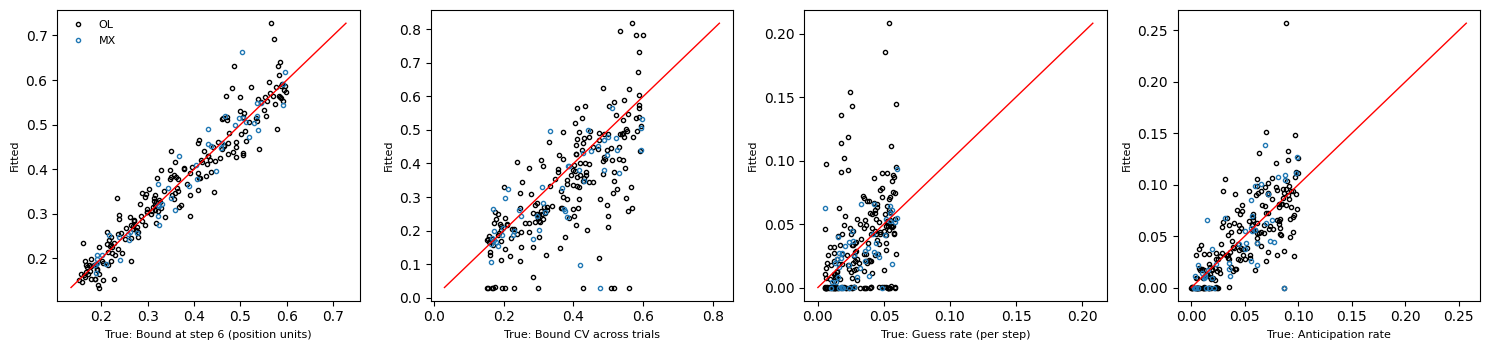

In [2]:
recovery = pd.read_pickle(PROCESSED / 'stopping_recovery.pkl')
print('converged:', recovery.groupby(['task', 'seed']).converged.first().groupby('task').mean().to_dict())

rows = []
for task, g in recovery.groupby('task'):
    s = g.groupby('seed').first()
    for k in ('sensory_std', 'ndt_p1', 'log_h_first', 'log_h_last'):
        rows.append({'task': task, 'block': 'shared', 'parameter': k, 'r': np.corrcoef(s[f'true_{k}'], s[f'fit_{k}'])[0, 1],
                     'median |error|': np.median(np.abs(s[f'fit_{k}'] - s[f'true_{k}']))})
    for b, gb in g.groupby('block'):
        for k in ('bound_scale', 'bound_cv', 'guess_rate', 'lapse_rate', 'anticipation_rate'):
            rows.append({'task': task, 'block': f'B{b} (n={gb.n_trials.median():.0f})', 'parameter': k,
                         'r': np.corrcoef(gb[f'true_{k}'], gb[f'fit_{k}'])[0, 1],
                         'median |error|': np.median(np.abs(gb[f'fit_{k}'] - gb[f'true_{k}']))})
rec_table = pd.DataFrame(rows)
display(rec_table.pivot_table(index=['task', 'block'], columns='parameter', values='r').round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (k, label) in zip(axes, [('bound_scale', 'Bound at step 6 (position units)'), ('bound_cv', 'Bound CV across trials'),
                                 ('guess_rate', 'Guess rate (per step)'), ('anticipation_rate', 'Anticipation rate')]):
    for task, color in (('OL', 'k'), ('MX', 'tab:blue')):
        g = recovery[recovery.task == task]
        ax.plot(g[f'true_{k}'], g[f'fit_{k}'], 'o', mfc='none', color=color, ms=3, label=task)
    lims = [recovery[[f'true_{k}', f'fit_{k}']].min().min(), recovery[[f'true_{k}', f'fit_{k}']].max().max()]
    ax.plot(lims, lims, 'r-', lw=1)
    ax.set_xlabel(f'True: {label}', fontsize=8)
    ax.set_ylabel('Fitted', fontsize=8)
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Recovery (2026-10-10, current defaults).** All 48 fits converged. Each block's
bound level recovers very well (r = 0.94–0.99, including the 33-trial OL block);
bound CV moderately (0.6–0.9, except OL B6 0.30). The shared time course
(r = 0.73–0.89) and NDT (0.95–0.96) recover well; sensory noise well in OL (0.89),
less in MX (0.56). **Per-block guess rates recover poorly** (r = −0.09 to 0.67)
and lapse rates moderately (0.31–0.79); anticipation rates well (0.51–0.93). So
interpret guess and lapse rates at the group level, not per subject and block.

An earlier recovery run (MXSC counts, time course shared) checked mechanism
attribution: data generated by only guesses, only sensory noise, or only a
collapsing bound were each attributed to the right mechanism (guess-only data gave
a small spurious collapse, about −0.06 in log h at step 6).

## Fits to OL and MX

Fits come from `scripts/run_stopping_fits.py` (cached in
`data/processed/stopping_fits_<variant>.pkl`). Main variant: bound scale and CV,
guess, lapse and anticipation rates per block; the bound's time course, sensory
noise and NDT {1, 2} shared across a subject's blocks. Variants for comparison:
`per_block_tc` (time course per block), `flat` (no time course),
`shared_rates` (guess, lapse and anticipation shared across blocks), `ndt123`
(NDT 1–3), `no_noise` (sensory noise fixed at 0).

**Why this split (round 1, 2026-10-09).** A first round with bound parameters
(including the time course) per block and the three rates shared found, by AIC
summed over subjects: rates per block much better (ΔAIC −12,039 OL, −1,007 MX;
e.g. 33% of OL block-4 responses at RT = 1 vs. a much lower rate in blocks 2–3);
one time-course shape per subject better than per-block shapes (−846 OL, −398 MX);
a constant bound worse (+2,382, +903); no sensory noise worse (+1,975, +453); NDT
1–3 worse than 1–2 (+203, +252). Round-1 fits are archived in
`data/processed/stopping_fits_round1/`.

In [3]:
DATASETS = {'OL': [1, 2, 3, 4, 5, 6], 'MX': [1, 2, 3]}
tables = {task: get_stopping_model_trials(task, blocks) for task, blocks in DATASETS.items()}
VARIANT_NAMES = ['main', 'per_block_tc', 'flat', 'shared_rates', 'ndt123', 'no_noise']
fits_all = {v: pd.read_pickle(PROCESSED / f'stopping_fits_{v}.pkl')
            for v in VARIANT_NAMES if (PROCESSED / f'stopping_fits_{v}.pkl').exists()}
fits = fits_all['main']
by_subj = fits.groupby(['task', 'subject_index']).first()
print('variants available:', list(fits_all))
print('main: fits that did not converge, by task:', (~by_subj.success).groupby('task').sum().to_dict(),
      '| fits that raised:', int(by_subj.error.notna().sum()))

OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects
variants available: ['main', 'per_block_tc', 'flat', 'shared_rates', 'ndt123', 'no_noise']
main: fits that did not converge, by task: {'MX': 0, 'OL': 1} | fits that raised: 0


### Parameter estimates (main variant)

Median [interquartile range] across subjects. Bound parameters per block
(`bound_scale` = mean bound at step 6, in raw position units; step SD is 0.15 in
both tasks). OL blocks 1–3 have step mean 0.05 (SNR 1/3), blocks 4–6 have 0.15
(SNR 1); within each SNR, blocks 1/4, 2/5 and 3/6 are the no-penalty, coin-penalty
and step-penalty conditions. MX blocks 1–3 are the same reward conditions with
SNRs mixed. Shared parameters: one value per subject.

In [4]:
BOUND_PARAMS = ['bound_scale', 'bound_cv'] + [f'log_h_k{k}' for k in KNOTS if k != 6]
SHARED_NAMES = ['guess_rate', 'lapse_rate', 'anticipation_rate', 'sensory_std', 'ndt_p1']

def _med_iqr(x):
    q = np.nanpercentile(x, [25, 50, 75])
    return f'{q[1]:.3f} [{q[0]:.3f}, {q[2]:.3f}]'

param_table = fits.groupby(['task', 'group'])[BOUND_PARAMS].agg(_med_iqr)
param_table['n subjects'] = fits.groupby(['task', 'group']).size()
param_table['median trials'] = fits.groupby(['task', 'group']).n_trials.median()
display(param_table)
by_subj.groupby('task')[SHARED_NAMES].agg(_med_iqr)

bound_scale              bound_cv              log_h_k1  \
task group                                                                     
MX   B1     0.158 [0.108, 0.227]  0.501 [0.232, 0.847]  0.579 [0.363, 0.809]   
     B2     0.236 [0.154, 0.336]  0.406 [0.258, 0.655]  0.579 [0.363, 0.809]   
     B3     0.215 [0.124, 0.358]  0.245 [0.057, 0.506]  0.579 [0.363, 0.809]   
OL   B1     0.173 [0.076, 0.292]  0.416 [0.231, 0.607]  0.913 [0.477, 1.214]   
     B2     0.352 [0.171, 0.453]  0.394 [0.228, 0.549]  0.913 [0.477, 1.214]   
     B3     0.241 [0.148, 0.361]  0.357 [0.114, 0.536]  0.908 [0.451, 1.218]   
     B4     0.084 [0.050, 0.199]  0.818 [0.035, 1.245]  0.913 [0.477, 1.214]   
     B5     0.108 [0.068, 0.180]  0.422 [0.096, 0.767]  0.913 [0.477, 1.214]   
     B6     0.077 [0.048, 0.153]  0.413 [0.030, 0.781]  0.913 [0.477, 1.214]   

                          log_h_k16  n subjects  median trials  
task group                                                      
MX   B1      -0.123 [-0.250, 0.000]          60          114.0  
     B2      -0.123 [-0.250, 0.000]          60           91.5  
     B3      -0.123 [-0.250, 0.000]          60           46.5  
OL   B1     -0.161 [-0.302, -0.002]          60          111.0  
     B2     -0.161 [-0.302, -0.002]          60           64.0  
     B3     -0.163 [-0.304, -0.002]          59           33.0  
     B4     -0.161 [-0.302, -0.002]          60          149.5  
     B5     -0.161 [-0.302, -0.002]          60          121.0  
     B6     -0.161 [-0.302, -0.002]          60           78.0

,guess_rate,lapse_rate,anticipation_rate,sensory_std,ndt_p1
task,,,,,
MX,"0.057 [0.000, 0.199]","0.056 [0.018, 0.144]","0.000 [0.000, 0.053]","0.046 [0.005, 0.112]","0.502 [0.388, 0.744]"
OL,"0.096 [0.007, 0.259]","0.085 [0.025, 0.239]","0.018 [0.000, 0.285]","0.039 [0.009, 0.117]","0.557 [0.377, 0.864]"


### Bound time course, per block

`θ(j) / θ(6)` per block. Gray: subjects; red: median. Weakly constrained per block
(see recovery), so read as descriptive.

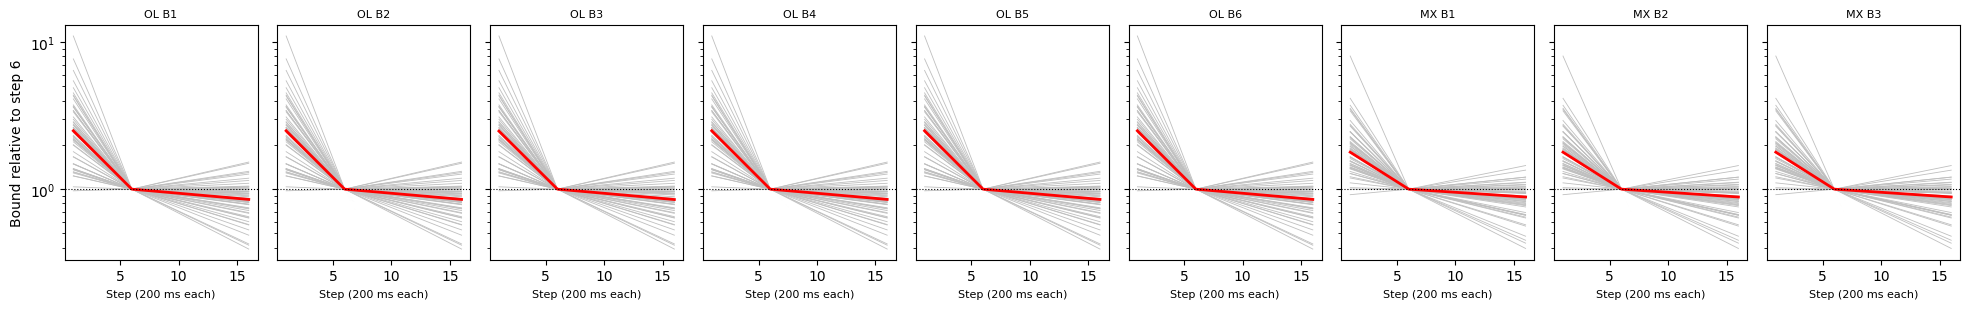

In [5]:
steps_ax = np.arange(1, 17)
conds = [(task, c) for task, d in tables.items() for c in sorted(d.condition.unique())]
fig, axes = plt.subplots(1, len(conds), figsize=(2.2 * len(conds), 3.2), sharey=True)
for ax, (task, c) in zip(axes, conds):
    s = fits[(fits.task == task) & (fits.group == c)]
    curves = np.array([bound_time_course({**row, 'bound_scale': 1.0}, steps_ax) for _, row in s.iterrows()])
    ax.plot(steps_ax, curves.T, color='0.75', lw=0.6)
    ax.plot(steps_ax, np.median(curves, axis=0), 'r-', lw=2)
    ax.axhline(1, color='k', ls=':', lw=0.8)
    ax.set_title(f'{task} {c}', fontsize=8)
    ax.set_xlabel('Step (200 ms each)', fontsize=8)
axes[0].set_ylabel('Bound relative to step 6')
axes[0].set_yscale('log')
plt.tight_layout()
plt.show()

### Model comparison across variants

Total negative log-likelihood and AIC (summed over subjects) per dataset. Lower
is better; AIC penalizes each free parameter by 2. AIC is a rough guide here
(the variants differ in flexibility in ways AIC handles imperfectly); held-out
likelihood is the planned check.

In [6]:
comp = []
for v, f in fits_all.items():
    s = f.groupby(['task', 'subject_index']).first()
    for task, g in s.groupby(level=0):
        comp.append({'variant': v, 'task': task, 'subjects': len(g), 'NLL': g.nll.sum(),
                     'AIC': (2 * g.nll + 2 * g.n_params).sum(), 'params / subject': g.n_params.median()})
comp = pd.DataFrame(comp)
comp['ΔAIC vs main'] = comp.AIC - comp.task.map(comp[comp.variant == 'main'].set_index('task').AIC)
comp.sort_values(['task', 'AIC']).round(1)

,variant,task,subjects,NLL,AIC,params / subject,ΔAIC vs main
0,main,MX,60,28079.3,58438.7,19.0,0.0
10,no_noise,MX,60,28258.1,58676.3,18.0,237.6
8,ndt123,MX,60,28171.2,58742.4,20.0,303.7
2,per_block_tc,MX,60,28028.3,58816.5,23.0,377.8
6,shared_rates,MX,60,28932.7,59425.4,13.0,986.7
4,flat,MX,60,28860.5,59761.0,17.0,1322.3
1,main,OL,60,62475.5,129021.0,34.0,0.0
9,ndt123,OL,60,62489.3,129168.5,35.0,147.6
3,per_block_tc,OL,60,62314.2,129894.5,44.0,873.5
11,no_noise,OL,60,63017.4,129984.7,33.0,963.8


### Does the model describe the data? (posterior predictive checks)

Each subject is simulated from their own fitted parameters, five times over their
real trials (same condition, step statistics and trial count). Real (black) vs.
model (red), pooled over subjects.

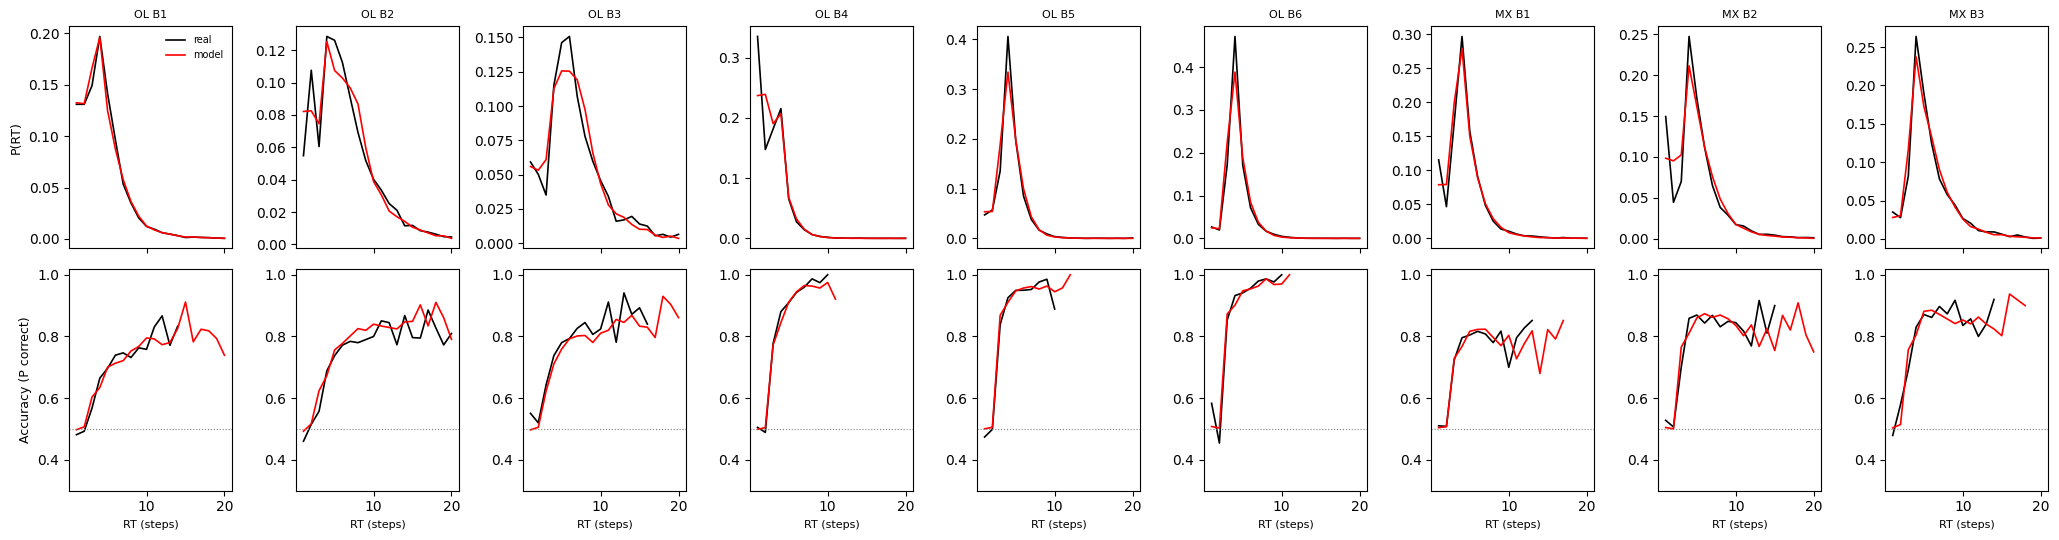

In [7]:
PPC_SEED = 11
PPC_REPS = 5
sims = {task: simulate_stopping_data_table(d, fits[fits.task == task], group_col='condition',
                                           num_reps=PPC_REPS, rng=np.random.default_rng(PPC_SEED))
        for task, d in tables.items()}

MAX_RT_SHOW = 20
rt_ax = np.arange(1, MAX_RT_SHOW + 1)
fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5), sharex=True)
for ci, (task, c) in enumerate(conds):
    real = tables[task][tables[task].condition == c]
    sim = sims[task][sims[task].condition == c]
    for t, col in ((real, 'k'), (sim, 'r')):
        axes[0, ci].plot(rt_ax, t.RT.value_counts(normalize=True).reindex(rt_ax, fill_value=0), '-', color=col, lw=1.2)
        acc = t.groupby('RT').correct.agg(['mean', 'size']).reindex(rt_ax)
        acc.loc[acc['size'] < 20, 'mean'] = np.nan
        axes[1, ci].plot(rt_ax, acc['mean'], '-', color=col, lw=1.2)
    axes[0, ci].set_title(f'{task} {c}', fontsize=8)
    axes[1, ci].axhline(0.5, color='gray', ls=':', lw=0.8)
    axes[1, ci].set_ylim(0.3, 1.02)
    axes[1, ci].set_xlabel('RT (steps)', fontsize=8)
axes[0, 0].set_ylabel('P(RT)', fontsize=9)
axes[1, 0].set_ylabel('Accuracy (P correct)', fontsize=9)
axes[0, 0].legend(['real', 'model'], fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

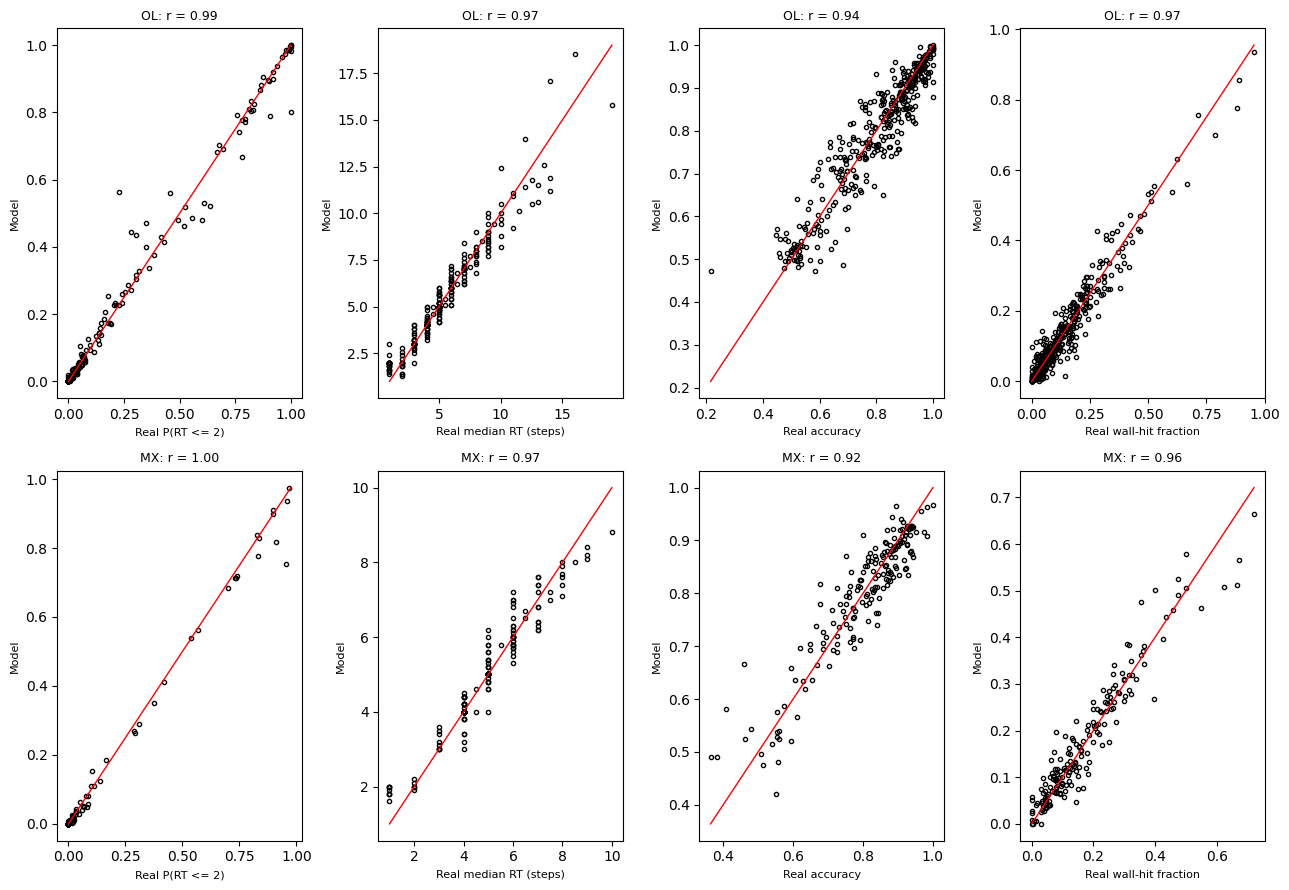

,task,statistic,r,mean real,mean model
0,OL,P(RT <= 2),0.994,0.129,0.130
1,OL,median RT (steps),0.973,5.056,5.102
2,OL,accuracy,0.936,0.791,0.788
3,OL,wall-hit fraction,0.969,0.147,0.146
4,MX,P(RT <= 2),0.997,0.087,0.083
5,MX,median RT (steps),0.968,4.822,4.876
6,MX,accuracy,0.923,0.797,0.796
7,MX,wall-hit fraction,0.957,0.174,0.178


In [8]:
def _subject_stats(t):
    g = t.groupby(['subject_index', 'condition'])
    return pd.DataFrame({'P(RT <= 2)': g.RT.apply(lambda r: np.mean(r <= 2)),
                         'median RT (steps)': g.RT.median(),
                         'accuracy': g.correct.mean(),
                         'wall-hit fraction': g.wall_hit.mean()})

STAT_NAMES = ['P(RT <= 2)', 'median RT (steps)', 'accuracy', 'wall-hit fraction']
fig, axes = plt.subplots(len(DATASETS), len(STAT_NAMES), figsize=(13, 9))
ppc_rows = []
for ti, task in enumerate(DATASETS):
    real = _subject_stats(tables[task])
    sim = sims[task].groupby('rep').apply(_subject_stats).groupby(level=[1, 2]).mean()
    both = real.join(sim, rsuffix=' model')
    for si, s in enumerate(STAT_NAMES):
        ax = axes[ti, si]
        ax.plot(both[s], both[f'{s} model'], 'o', mfc='none', color='k', ms=3)
        lims = [np.nanmin(both[[s, f'{s} model']].values), np.nanmax(both[[s, f'{s} model']].values)]
        ax.plot(lims, lims, 'r-', lw=1)
        rr = both[[s, f'{s} model']].corr().iloc[0, 1]
        ax.set_title(f'{task}: r = {rr:.2f}', fontsize=9)
        ax.set_xlabel(f'Real {s}', fontsize=8)
        ax.set_ylabel('Model', fontsize=8)
        ppc_rows.append({'task': task, 'statistic': s, 'r': rr,
                         'mean real': np.nanmean(both[s]), 'mean model': np.nanmean(both[f'{s} model'])})
plt.tight_layout()
plt.show()
pd.DataFrame(ppc_rows).round(3)

### Figure03S03's statistics: incongruence and premature crossings

The same definitions as Figure03S03 (`pigeon.data.get_crossing_diagnostics`),
computed on real data and on the model's simulated data after running both
through the real-data bound pipeline (`get_bounds` per subject; trials passing
`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10, not a wall hit). Binned by
the inferred |bound| (0.1 wide). Per-subject bin means (≥ 5 trials), then mean ± SEM across
subjects (≥ 3 subjects). Figure03S03's fixed-bound scenarios could not reproduce
the incongruence floor at large bounds, or premature crossings with plausible NDTs.

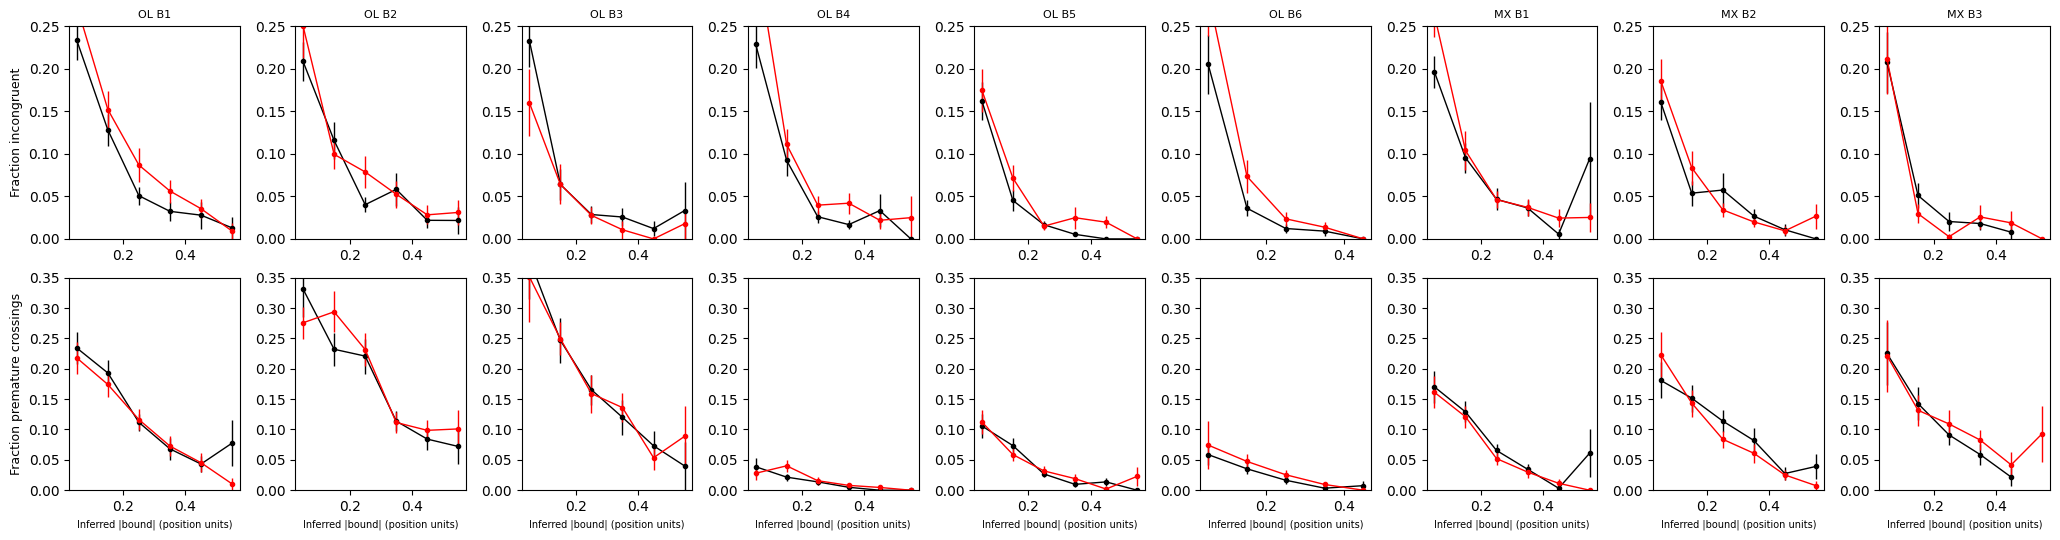

In [9]:
BIN_WIDTH = {'OL': 0.1, 'MX': 0.1}

def _diagnostics(t):
    t = t[get_good_trial_array(t, min_dt=2, min_trial_number=10)].copy()
    t[['incongruent', 'premature_crossing']] = get_crossing_diagnostics(t).values
    return t

def _binned(t, col, width, min_trials=5, min_subj=3):
    t = t.assign(_bin=np.floor(t.abs_bound / width))
    per_subj = t.groupby(['subject_index', '_bin'])[col].agg(['mean', 'size'])
    per_subj = per_subj[per_subj['size'] >= min_trials]['mean']
    g = per_subj.groupby(level='_bin').agg(['mean', 'sem', 'size'])
    g = g[g['size'] >= min_subj]
    return (g.index.to_numpy() + 0.5) * width, g['mean'].to_numpy(), g['sem'].to_numpy()

diag_real = {task: _diagnostics(d) for task, d in tables.items()}
diag_sim = {task: _diagnostics(infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99))
            for task, s in sims.items()}

fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5))
for ci, (task, c) in enumerate(conds):
    for ri, col in enumerate(('incongruent', 'premature_crossing')):
        ax = axes[ri, ci]
        for t, color in ((diag_real[task], 'k'), (diag_sim[task], 'r')):
            x, y, e = _binned(t[t.condition == c], col, BIN_WIDTH[task])
            ax.errorbar(x, y, yerr=e, fmt='o-', color=color, ms=3, lw=1, capsize=0)
        ax.set_ylim(0, 0.35 if ri else 0.25)
        if ri == 0:
            ax.set_title(f'{task} {c}', fontsize=8)
        else:
            ax.set_xlabel('Inferred |bound| (position units)', fontsize=7)
axes[0, 0].set_ylabel('Fraction incongruent', fontsize=9)
axes[1, 0].set_ylabel('Fraction premature crossings', fontsize=9)
plt.tight_layout()
plt.show()

### How many guesses survive the standard DT ≥ 2 filter?

In the simulated data each commit's source is known (bound crossing, guess or
anticipation). After the real-data bound pipeline and the paper's filter
(`get_good_trial_array`), what fraction of the surviving trials are guesses or
anticipations?

In [10]:
guess_rows = []
for task, s in sims.items():
    t = infer_bounds_like_data(s[s.rep == 0]).assign(trial_number=99)
    l_pass = get_good_trial_array(t, min_dt=2, min_trial_number=10)
    for c, tc in t.groupby('condition'):
        lp = l_pass.loc[tc.index]
        nonbound = tc.commit_type.isin(['guess', 'anticipation'])
        guess_rows.append({'task': task, 'condition': c,
                           'guess + anticipation, all trials': nonbound.mean(),
                           'guess + anticipation, passing filter': nonbound[lp].mean(),
                           'lapse, passing filter': tc.lapse[lp].mean(),
                           'fraction of trials passing': lp.mean()})
pd.DataFrame(guess_rows).round(3)

,task,condition,"guess + anticipation, all trials","guess + anticipation, passing filter","lapse, passing filter",fraction of trials passing
0,OL,B1,0.470,0.227,0.148,0.470
1,OL,B2,0.321,0.170,0.110,0.621
2,OL,B3,0.229,0.133,0.045,0.711
3,OL,B4,0.586,0.132,0.072,0.231
4,OL,B5,0.199,0.090,0.022,0.463
5,OL,B6,0.139,0.086,0.024,0.492
6,MX,B1,0.314,0.161,0.086,0.446
7,MX,B2,0.286,0.086,0.059,0.475
8,MX,B3,0.172,0.097,0.029,0.580


### Interpretation (2026-10-10, round 2)

- **Model comparison (AIC, summed over subjects):** the main model (bound scale,
  CV and the three rates per block; time course, noise and NDT shared) is best in
  both datasets. Next best: NDT 1–3 (+148 OL, +304 MX), per-block time courses
  (+874, +378), no sensory noise (+964, +238), constant bound (+3,097, +1,322),
  shared rates (+12,068, +987).
- **Fit quality:** per-subject P(RT ≤ 2), median RT, accuracy and wall-hit rate
  are reproduced (r = 0.92–1.0), as are RT distributions and accuracy by RT.
  Figure03S03's incongruence and premature-crossing curves are now matched in all
  OL and MX blocks, including the high-SNR OL blocks, with NDT ≤ 2. Remaining
  misfit: real RT distributions often have more responses at RT = 1 and fewer at
  RT = 2 than the model, which spreads anticipations uniformly over the first
  NDT + 1 frames; anticipations may all be first-frame presses.
- **Bound time course:** the bound is ~2.5× (OL) / ~1.8× (MX) higher at step 1
  than at step 6, then 10–15% lower again by step 16.
- **Guesses, anticipations, lapses:** concentrated in the first block of each SNR
  (OL B1, B4; MX B1). After the paper's filter (DT ≥ 2, no wall hits,
  trial_number ≥ 10), simulated trials from the fitted model are still 9–23%
  guesses or anticipations and 2–15% lapses, depending on block. Per-block guess
  and lapse rates are only moderately recoverable, so these are group-level
  estimates.
- **Noise vs. bound variability vs. guesses** partly trade off: with rates shared
  (round 1), sensory noise was ~0.10 and bound CV often at its floor; with rates
  per block, noise is ~0.04 and bound CV ~0.4. Conclusions about the source of
  trial-to-trial variability should wait for a targeted check.